
# SBI Financial Performance Analysis

## 1. Project Overview

This notebook analyses the financial performance of State Bank of India (SBI) over five financial years, from FY2021–22 to FY2025–26.

The analysis focuses on SBI's business growth, income and profitability, financial ratios, asset quality, capital adequacy, and shareholder value.

The objective is to use historical financial data to identify important trends, evaluate performance across key financial indicators, and develop meaningful business insights.

## 2. Business Objective

The primary objective of this analysis is to understand how SBI's financial performance has evolved over the selected five-year period.

The analysis aims to answer the following questions:

- How has SBI's overall business size changed?
- How have income and profitability evolved?
- What trends are visible in profitability ratios?
- How have shareholder value indicators changed?
- Has SBI's asset quality improved?
- How has its capital adequacy position evolved?
- What do CASA and Cost-to-Income trends indicate about funding composition and operating efficiency?

## 3. Analysis Scope

| Parameter | Description |
|---|---|
| Bank | State Bank of India (SBI) |
| Analysis Period | FY2021–22 to FY2025–26 |
| Data Frequency | Annual |
| Analysis Type | Historical Financial Analysis |
| Number of Analytical Questions | 8 analytical question IDs covered across 7 analysis sections |
| Primary Tool | Python |
| Libraries | Pandas, NumPy, Matplotlib |
| Financial Unit | INR crore |
| Ratio Unit | Percentage |
| Per-share Unit | INR per share |

## 4. Analytical Approach

The analysis follows a structured approach:

1. Load the consolidated financial KPI dataset.
2. Filter the records for State Bank of India.
3. Organise financial observations by financial year.
4. Calculate or present relevant metrics using the source-reported values.
5. Create summary tables for each analytical question.
6. Visualise historical trends using line charts.
7. Interpret the results and document business insights.

The analysis uses reported financial values and ratios from the consolidated dataset. Source-reported growth figures are retained rather than independently recalculated unless explicitly stated.

## 5. Data Source and Disclosure

The financial dataset was compiled using publicly available bank financial disclosures and annual reports.

This is an independent portfolio analysis conducted using publicly available information. It is not commissioned by, affiliated with, or approved by State Bank of India.

Any stakeholder perspectives or business interpretations presented in this project are analytical assumptions and do not represent actual SBI stakeholder consultations.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

### Dataset Overview

Before beginning the financial performance analysis, a brief overview of the consolidated financial dataset is presented to understand its size, structure and coverage.

The dataset contains financial KPI records for SBI and five selected peer banks across five financial years, from FY2021–22 to FY2025–26. It includes 26 columns in total: 3 identification columns and 23 financial performance indicators covering profitability, growth, asset quality, capital adequacy, operational efficiency and other banking metrics.

In [5]:
kpi_path = Path.cwd().parent.parent / "08_Data_Understanding_Preparation" / "02_Consolidated_Data" / "Bank_Financial_Performance_KPI_Data.xlsx"

df = pd.read_excel(kpi_path)

# Dataset Overview

total_records = df.shape[0]
total_columns = df.shape[1]

# Count SBI records
sbi_records = df[
    df["Bank"].astype(str).str.contains(
        "SBI|State Bank of India", case=False, na=False
    )
].shape[0]

# Identify financial years
financial_years = sorted(df["Financial Year"].dropna().unique())

# Display summary
print("DATASET OVERVIEW")
print("-" * 35)

print("Total Records:", total_records)
print("Total Columns:", total_columns)
print("SBI Records:", sbi_records)
print("Financial Years Covered:", ", ".join(financial_years))
print("Number of Financial Years:", len(financial_years))

DATASET OVERVIEW
-----------------------------------
Total Records: 30
Total Columns: 26
SBI Records: 5
Financial Years Covered: FY2021-22, FY2022-23, FY2023-24, FY2024-25, FY2025-26
Number of Financial Years: 5


### AQ-001 -- How have SBI's Total Assets, Total Deposits and Gross Advances changed over FY2021–22 to FY2025–26?
### AQ-002 -- How have SBI's Total Assets Growth %, Deposit Growth % and Gross Advances Growth % changed over FY2021–22 to FY2025–26?

In [8]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "Total Assets (₹ crore)": sbi["Total Assets (₹ crore)"],
    "Total Assets Growth (%)": (sbi["Total Assets Growth (%)"] * 100),
    "Total Deposits (₹ crore)": sbi["Total Deposits (₹ crore)"],
    "Total Deposit Growth (%)": (sbi["Deposit Growth (%)"] * 100),
    "Gross Advances (₹ crore)": sbi["Gross Advances (₹ crore)"],
    "Gross Advances Growth (%)": (sbi["Gross Advances Growth (%)"] * 100)
})

results.reset_index(drop=True).round(2)

,Financial Year,Total Assets (₹ crore),Total Assets Growth (%),Total Deposits (₹ crore),Total Deposit Growth (%),Gross Advances (₹ crore),Gross Advances Growth (%)
0,FY2021-22,4987597.0,9.99,4051534.0,10.06,2818000.0,11.00
1,FY2022-23,5516979.0,10.61,4423778.0,9.19,3269000.0,16.00
2,FY2023-24,6179694.0,12.01,4916077.0,11.13,3768000.0,15.26
3,FY2024-25,6676053.0,8.03,5382190.0,9.48,4221000.0,12.02
4,FY2025-26,7623012.0,14.18,5975642.0,11.03,4933000.0,16.87


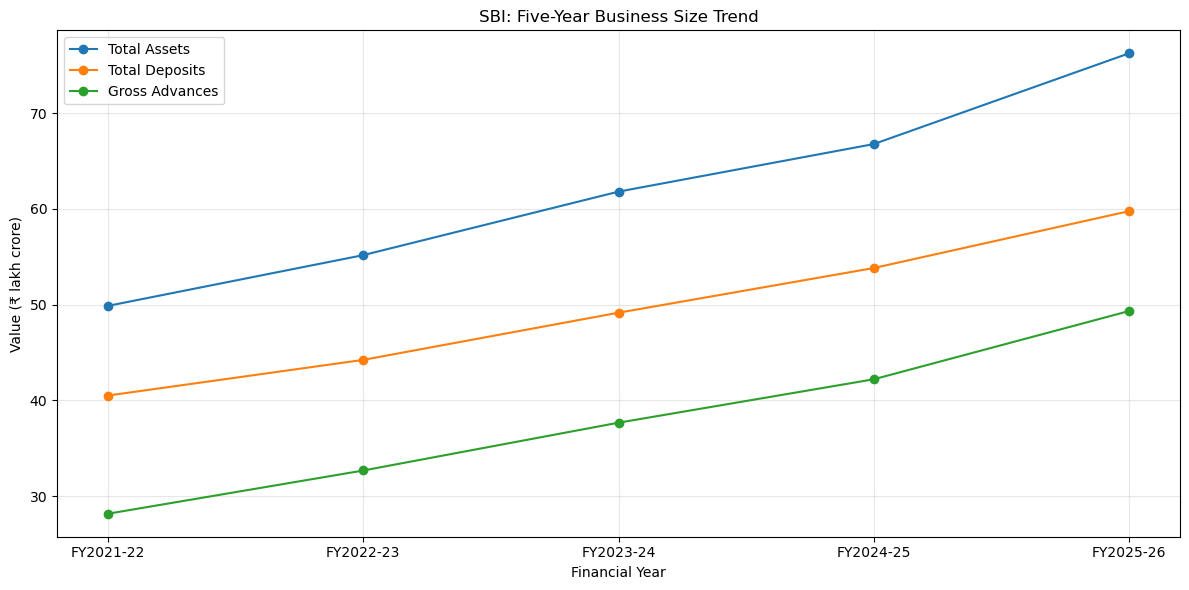

In [10]:
kpis = [
    "Total Assets (₹ crore)",
    "Total Deposits (₹ crore)",
    "Gross Advances (₹ crore)"
]

plt.figure(figsize=(12, 6))
for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi] / 100000,
        marker="o",
        label=kpi.replace(" (₹ crore)", "")
    )

plt.title("SBI: Five-Year Business Size Trend")
plt.xlabel("Financial Year")
plt.ylabel("Value (₹ lakh crore)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Answer and Key Insights

SBI demonstrated consistent business expansion across all three major balance-sheet indicators during FY2021–22 to FY2025–26.

- **Total Assets:** Increased from ₹49.88 lakh crore in FY2021–22 to ₹76.23 lakh crore in FY2025–26. The highest reported annual growth was 14.18% in FY2025–26.
- **Total Deposits:** Increased from ₹40.52 lakh crore to ₹59.76 lakh crore over the five-year period. Deposit growth remained relatively stable, ranging from 9.19% to 11.13% during FY2022–23 to FY2025–26.
- **Gross Advances:** Increased from ₹28.18 lakh crore to ₹49.33 lakh crore. Advances recorded stronger growth than deposits in each year from FY2022–23 to FY2025–26, with the highest growth of 16.87% in FY2025–26.

### Business Interpretation

SBI experienced sustained expansion in its overall business size. Gross advances grew faster than deposits during the observed period, indicating that lending expanded at a faster pace than deposit mobilisation.

This trend is worth monitoring because the relationship between deposit growth and credit growth can influence a bank's funding requirements and liquidity management.

### Conclusion

SBI recorded strong growth in assets, deposits and advances over the five financial years. FY2025–26 showed particularly strong expansion, with the highest annual growth in assets and advances.

*Note: AQ-002 is addressed together with AQ-001 because both questions examine the same three financial indicators. FY2021–22 growth figures are source-reported; the previous financial year's values are outside the dataset.*


### AQ-003 -- How have SBI's Net Interest Income (NII), Operating Profit and Net Profit (PAT) changed over FY2021–22 to FY2025–26?

In [14]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "Net Interest Income (₹ crore)": sbi["Net Interest Income (NII) (₹ crore)"],
    "NII Growth (%)": sbi["NII Growth (%)"] * 100,
    "Operating Profit (₹ crore)": sbi["Operating Profit (₹ crore)"],
    "Operating Profit Growth (%)": sbi["Operating Profit Growth (%)"] * 100,
    "Net Profit (₹ crore)": sbi["Net Profit (PAT) (₹ crore)"],
    "Net Profit Growth (%)": sbi["Net Profit Growth (%)"] * 100
})
results.reset_index(drop=True).round(2)

,Financial Year,Net Interest Income (₹ crore),NII Growth (%),Operating Profit (₹ crore),Operating Profit Growth (%),Net Profit (₹ crore),Net Profit Growth (%)
0,FY2021-22,120708.0,9.03,75292.0,5.22,31676.0,55.20
1,FY2022-23,144841.0,19.99,83713.0,11.18,50232.0,58.58
2,FY2023-24,159876.0,10.38,93797.0,12.05,61077.0,21.59
3,FY2024-25,166340.0,4.04,110579.0,17.89,70901.0,16.08
4,FY2025-26,173120.0,4.08,123015.0,11.25,80032.0,12.88


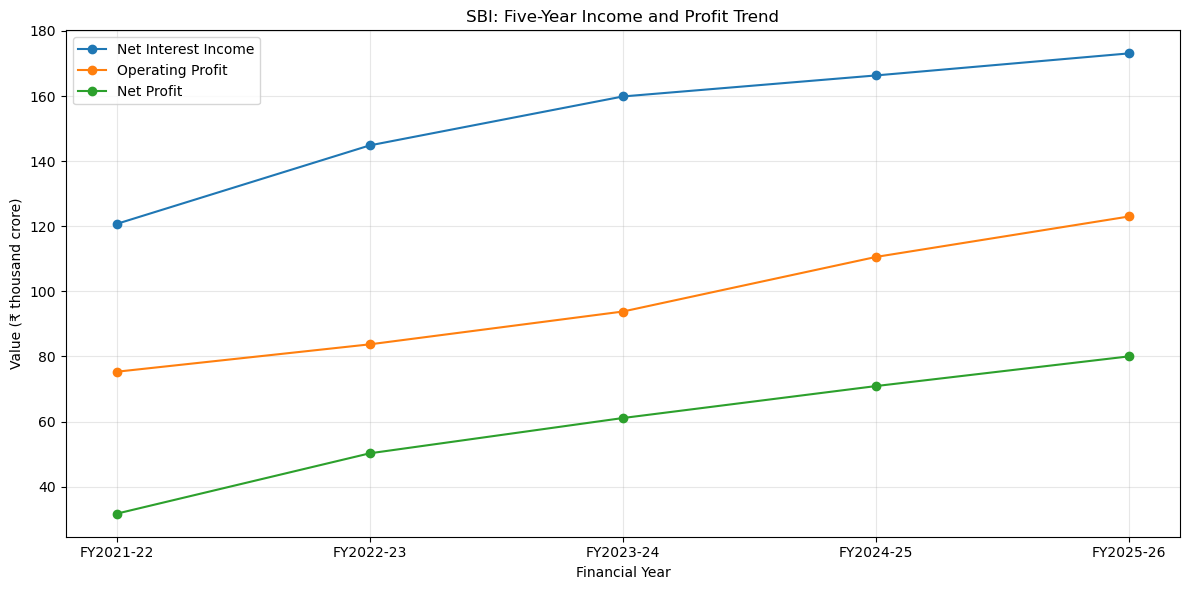

In [16]:
kpis = [
    "Net Interest Income (NII) (₹ crore)",
    "Operating Profit (₹ crore)",
    "Net Profit (PAT) (₹ crore)"
]

plt.figure(figsize=(12, 6))

for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi] / 1000,
        marker="o",
        label=kpi.replace(" (₹ crore)", "").replace(" (NII)", "").replace(" (PAT)", "")
    )

plt.title("SBI: Five-Year Income and Profit Trend")
plt.xlabel("Financial Year")
plt.ylabel("Value (₹ thousand crore)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Answer and Key Insights

SBI recorded consistent growth in Net Interest Income (NII), Operating Profit and Net Profit (PAT) throughout FY2021–22 to FY2025–26.

- **Net Interest Income (NII):** Increased from ₹1,20,708 crore to ₹1,73,120 crore. However, annual growth slowed from 19.99% in FY2022–23 to approximately 4% in FY2024–25 and FY2025–26.
- **Operating Profit:** Increased from ₹75,292 crore to ₹1,23,015 crore. Its highest reported annual growth was 17.89% in FY2024–25.
- **Net Profit (PAT):** Increased from ₹31,676 crore to ₹80,032 crore. PAT recorded particularly strong growth in FY2022–23 (58.58%), followed by a gradual moderation in annual growth.

### Business Interpretation

The increase in all three indicators reflects an improvement in SBI's reported income and profitability over the period.

However, the growth rates show that the pace of expansion was not uniform. NII growth moderated considerably after FY2022–23, while Operating Profit continued to record comparatively stronger growth in subsequent years.

Net Profit continued to increase despite its annual growth rate slowing. This distinction is important: an increase in profit does not necessarily mean the rate of profit growth is accelerating.

### Conclusion

SBI achieved sustained growth in income and profitability across the five-year period. The key observation is that absolute profits continued to increase, although growth rates moderated for NII and PAT towards the end of the period.


### AQ-004 -- How did SBI's Net Interest Margin (NIM) and Return on Assets (ROA) change over FY2021–22 to FY2025–26?

In [20]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "Net Interest Margin (NIM) (%)": sbi["Net Interest Margin (NIM) (%)"],
    "Return on Assets (ROA) (%)": sbi["Return on Assets (ROA) (%)"]
})

results.reset_index(drop=True).round(2)

,Financial Year,Net Interest Margin (NIM) (%),Return on Assets (ROA) (%)
0,FY2021-22,3.12,0.67
1,FY2022-23,3.37,0.96
2,FY2023-24,3.28,1.04
3,FY2024-25,3.09,1.10
4,FY2025-26,2.91,1.12


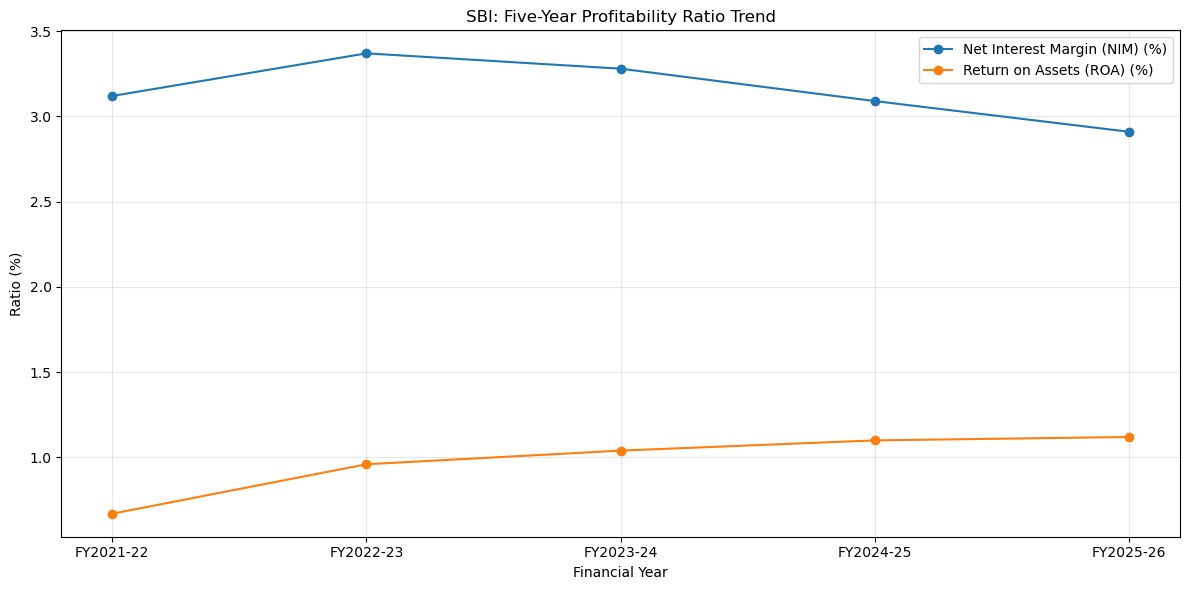

In [22]:
kpis = [
    "Net Interest Margin (NIM) (%)",
    "Return on Assets (ROA) (%)"
]

plt.figure(figsize=(12, 6))

for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi],
        marker="o",
        label=kpi
    )

plt.title("SBI: Five-Year Profitability Ratio Trend")
plt.xlabel("Financial Year")
plt.ylabel("Ratio (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Answer and Key Insights

SBI's Net Interest Margin (NIM) and Return on Assets (ROA) followed different trends during FY2021–22 to FY2025–26.

- **Net Interest Margin (NIM):** Increased from 3.12% in FY2021–22 to 3.37% in FY2022–23, before declining gradually to 2.91% in FY2025–26.
- **Return on Assets (ROA):** Improved consistently from 0.67% in FY2021–22 to 1.12% in FY2025–26.

### Business Interpretation

The declining NIM in the later years indicates that the bank's reported net interest margin narrowed. NIM measures the relationship between net interest income and interest-earning assets, making it an important indicator of interest-related profitability.

In contrast, the consistent improvement in ROA indicates that SBI generated more reported profit relative to its asset base over the observed period.

The two indicators together show that a declining interest margin did not coincide with declining overall returns on assets.

### Conclusion

SBI's profitability performance showed a mixed trend: NIM declined after FY2022–23, while ROA improved throughout the five-year period. This highlights the importance of examining multiple profitability indicators rather than relying on NIM alone.


### AQ-005 -- How did SBI's reported Earnings Per Share (EPS) and Book Value Per Share change over FY2021–22 to FY2025–26?

In [26]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "Earnings Per Share (₹/share)": sbi["Earnings Per Share (EPS) (₹/share)"],
    "Book Value Per Share (₹/share)": sbi["Book Value Per Share (₹/share)"]
})

results.reset_index(drop=True).round(2)

,Financial Year,Earnings Per Share (₹/share),Book Value Per Share (₹/share)
0,FY2021-22,35.49,269.48
1,FY2022-23,56.29,309.89
2,FY2023-24,68.44,363.84
3,FY2024-25,79.44,435.95
4,FY2025-26,87.59,512.31


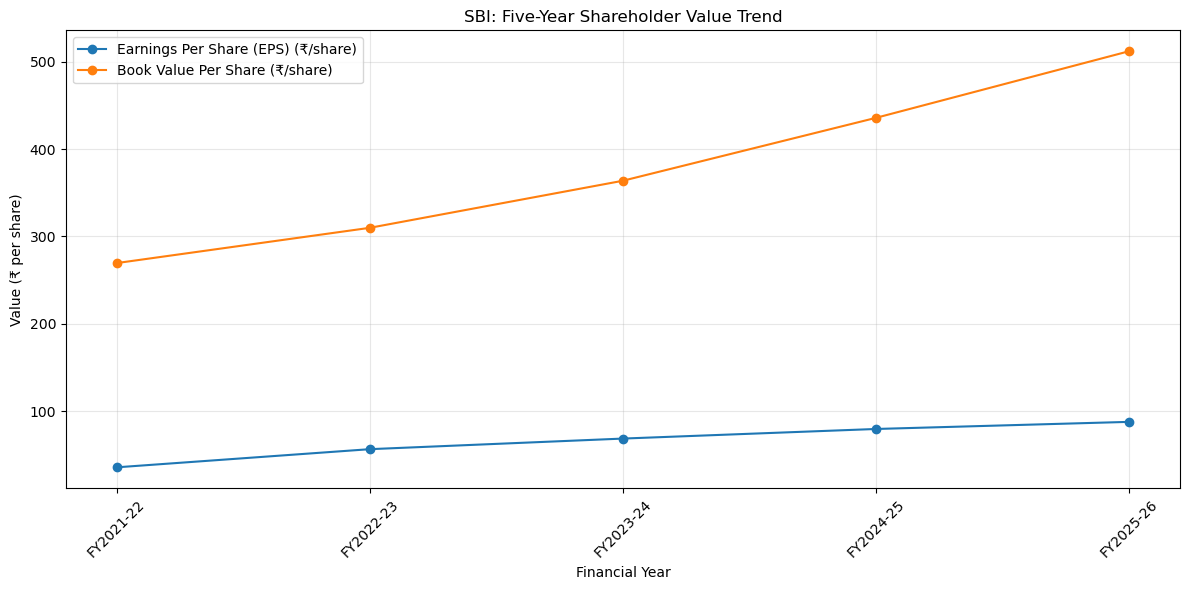

In [28]:
kpis = [
    "Earnings Per Share (EPS) (₹/share)",
    "Book Value Per Share (₹/share)"
]

plt.figure(figsize=(12, 6))

for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi],
        marker="o",
        label=kpi
    )

plt.title("SBI: Five-Year Shareholder Value Trend")
plt.xlabel("Financial Year")
plt.ylabel("Value (₹ per share)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Answer and Key Insights

Both Earnings Per Share (EPS) and Book Value Per Share increased consistently during FY2021–22 to FY2025–26.

- **Earnings Per Share (EPS):** Increased from ₹35.49 in FY2021–22 to ₹87.59 in FY2025–26.
- **Book Value Per Share:** Increased from ₹269.48 to ₹512.31 over the same period.

### Business Interpretation

The consistent increase in EPS indicates that reported earnings attributable to each share improved over the observed period.

The increase in Book Value Per Share indicates growth in the reported book value attributable to each share. Together, these indicators provide a positive view of the bank's reported earnings and shareholder equity position.

However, these measures alone do not establish whether the stock is undervalued or overvalued. That would require additional market-based indicators such as share price, Price-to-Earnings (P/E) ratio and Price-to-Book (P/B) ratio.

### Conclusion

SBI demonstrated consistent improvement in both EPS and Book Value Per Share across the five financial years, indicating growth in reported earnings and book value per share.


### AQ-006 -- How did SBI's reported Gross NPA (GNPA) Ratio, Net NPA (NNPA) Ratio and Provision Coverage Ratio (PCR) change over FY2021–22 to FY2025–26?

In [32]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "GNPA Ratio (%)": sbi["Gross NPA (GNPA) Ratio (%)"],
    "NNPA Ratio (%)": sbi["Net NPA (NNPA) Ratio (%)"],
    "Provision Coverage Ratio (%)": sbi["Provision Coverage Ratio (PCR) (%)"]
})

results.reset_index(drop=True).round(2)

,Financial Year,GNPA Ratio (%),NNPA Ratio (%),Provision Coverage Ratio (%)
0,FY2021-22,3.97,1.02,90.20
1,FY2022-23,2.78,0.67,91.91
2,FY2023-24,2.24,0.57,91.89
3,FY2024-25,1.82,0.47,92.08
4,FY2025-26,1.49,0.39,91.97


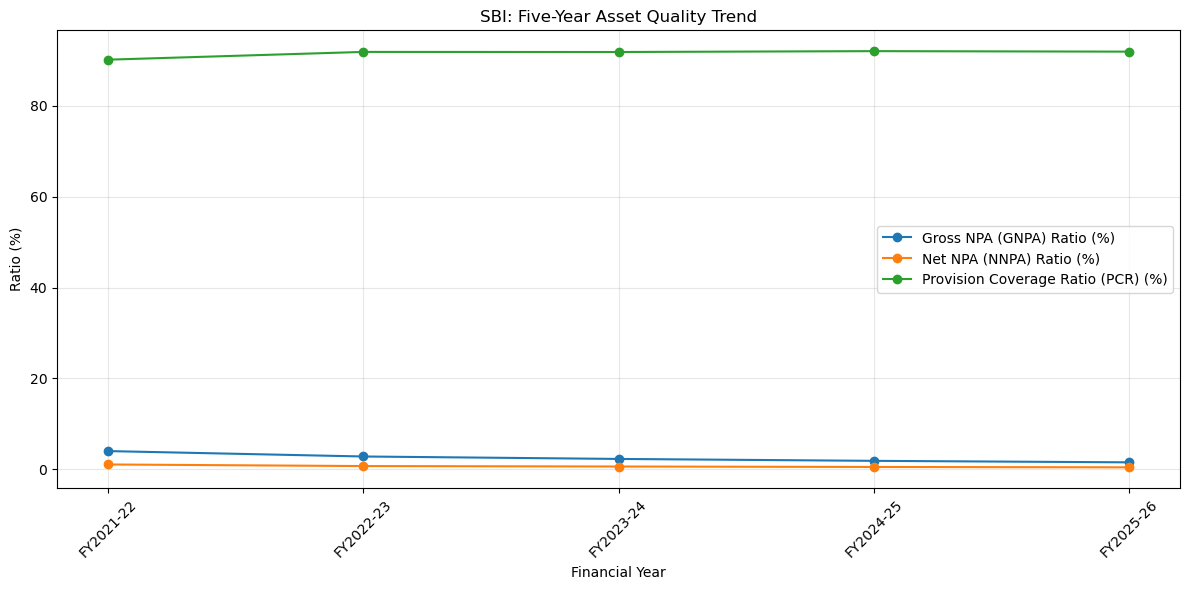

In [34]:
kpis = [
    "Gross NPA (GNPA) Ratio (%)",
    "Net NPA (NNPA) Ratio (%)",
    "Provision Coverage Ratio (PCR) (%)"
]

plt.figure(figsize=(12, 6))

for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi],
        marker="o",
        label=kpi
    )

plt.title("SBI: Five-Year Asset Quality Trend")
plt.xlabel("Financial Year")
plt.ylabel("Ratio (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Answer and Key Insights

SBI's asset quality indicators showed a consistent improvement during FY2021–22 to FY2025–26.

- **Gross NPA (GNPA) Ratio:** Declined from 3.97% to 1.49%.
- **Net NPA (NNPA) Ratio:** Declined from 1.02% to 0.39%.
- **Provision Coverage Ratio (PCR):** Increased from 90.20% in FY2021–22 to 91.97% in FY2025–26, remaining broadly stable around 92% throughout the period.

### Business Interpretation

The decline in GNPA and NNPA indicates an improvement in the reported quality of SBI's loan portfolio, with a smaller proportion of advances classified as non-performing.

The consistently high PCR indicates that SBI maintained a substantial level of provisioning coverage against its reported non-performing assets.

These indicators should be interpreted together. Lower NPA ratios indicate improvement in asset quality, while a higher PCR generally indicates stronger provisioning coverage.

### Conclusion

SBI demonstrated substantial improvement in reported asset quality over the five-year period. Both GNPA and NNPA declined consistently, while PCR remained high and relatively stable.



### AQ-007 -- How did SBI's reported Capital Adequacy Ratio (CRAR) and Common Equity Tier 1 (CET1) Ratio change over FY2021–22 to FY2025–26?

In [38]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "Capital Adequacy Ratio (CRAR) (%)": sbi["Capital Adequacy Ratio (CRAR) (%)"],
    "Common Equity Tier 1 (CET1) Ratio (%)": sbi["Common Equity Tier 1 (CET1) Ratio (%)"]
})

results.reset_index(drop=True).round(2)

,Financial Year,Capital Adequacy Ratio (CRAR) (%),Common Equity Tier 1 (CET1) Ratio (%)
0,FY2021-22,13.83,9.94
1,FY2022-23,14.68,10.27
2,FY2023-24,14.28,10.36
3,FY2024-25,14.25,10.81
4,FY2025-26,15.40,12.29


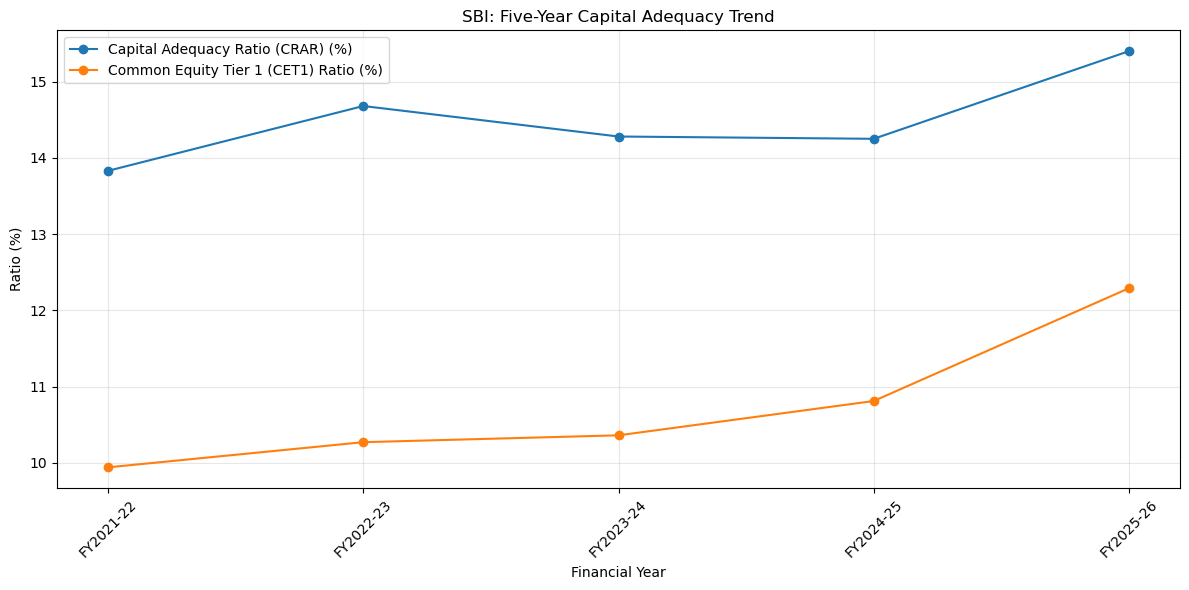

In [40]:
kpis = [
    "Capital Adequacy Ratio (CRAR) (%)",
    "Common Equity Tier 1 (CET1) Ratio (%)"
]

plt.figure(figsize=(12, 6))

for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi],
        marker="o",
        label=kpi
    )

plt.title("SBI: Five-Year Capital Adequacy Trend")
plt.xlabel("Financial Year")
plt.ylabel("Ratio (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Answer and Key Insights

SBI maintained its capital adequacy ratios above their FY2021–22 levels and recorded an overall improvement by FY2025–26.

- **Capital Adequacy Ratio (CRAR):** Increased from 13.83% in FY2021–22 to 15.40% in FY2025–26. The ratio fluctuated slightly between FY2022–23 and FY2024–25 before increasing in FY2025–26.
- **Common Equity Tier 1 (CET1) Ratio:** Increased consistently from 9.94% to 12.29% across the five financial years.

### Business Interpretation

CRAR measures a bank's regulatory capital in relation to its risk-weighted assets. CET1 represents a higher-quality component of regulatory capital.

The overall increase in both indicators suggests that SBI strengthened its reported capital position during the observed period.

The consistent increase in CET1 is particularly noteworthy because it indicates an improvement in the proportion of core equity capital relative to risk-weighted assets.

### Conclusion

SBI recorded an overall improvement in capital adequacy between FY2021–22 and FY2025–26, with both CRAR and CET1 reaching their highest observed values in FY2025–26.


### AQ-008 -- How did SBI's reported CASA Ratio and Cost-to-Income Ratio change over FY2021–22 to FY2025–26?

In [44]:
sbi = df[df["Bank"] == "SBI"].sort_values("Financial Year")

results = pd.DataFrame({
    "Financial Year": sbi["Financial Year"],
    "CASA Ratio (%)": sbi["CASA Ratio (%)"],
    "Cost-to-Income Ratio (%)": sbi["Cost-to-Income Ratio (%)"]
})

results.reset_index(drop=True).round(2)

,Financial Year,CASA Ratio (%),Cost-to-Income Ratio (%)
0,FY2021-22,45.28,53.31
1,FY2022-23,43.80,53.87
2,FY2023-24,41.11,55.66
3,FY2024-25,39.97,51.64
4,FY2025-26,39.46,50.11


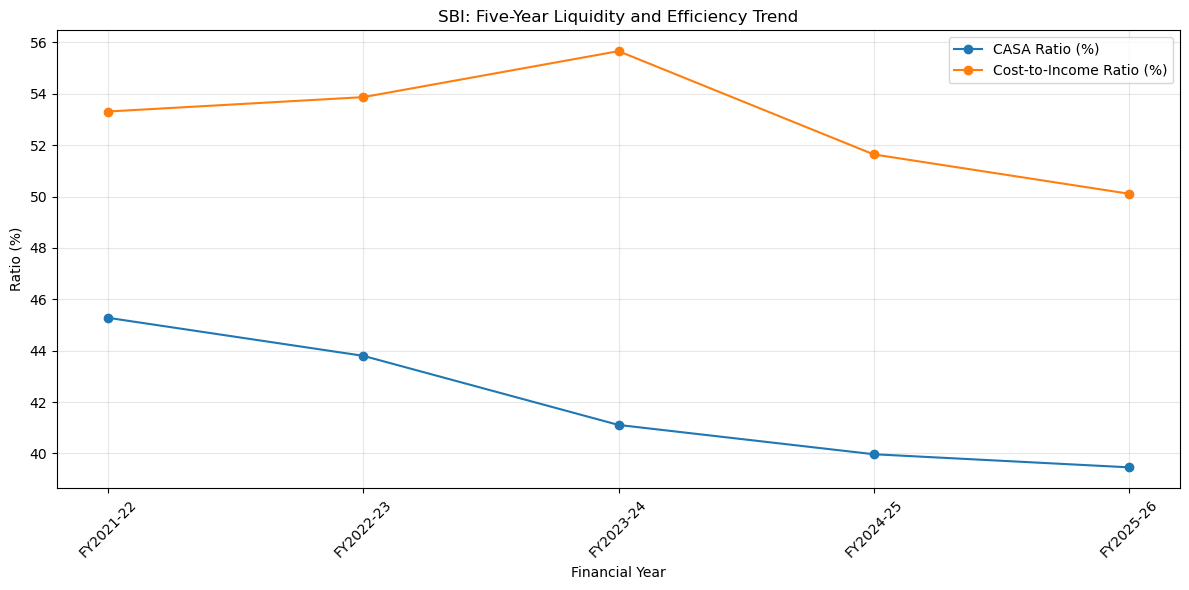

In [46]:
kpis = [
    "CASA Ratio (%)",
    "Cost-to-Income Ratio (%)"
]

plt.figure(figsize=(12, 6))

for kpi in kpis:
    plt.plot(
        sbi["Financial Year"],
        sbi[kpi],
        marker="o",
        label=kpi
    )

plt.title("SBI: Five-Year Liquidity and Efficiency Trend")
plt.xlabel("Financial Year")
plt.ylabel("Ratio (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


### Answer and Key Insights

SBI's CASA Ratio and Cost-to-Income Ratio followed different patterns during FY2021–22 to FY2025–26.

- **CASA Ratio:** Declined consistently from 45.28% in FY2021–22 to 39.46% in FY2025–26.
- **Cost-to-Income Ratio:** Increased from 53.31% in FY2021–22 to 55.66% in FY2023–24, before declining to 50.11% in FY2025–26.

### Business Interpretation

The decline in CASA indicates that the proportion of Current Account and Savings Account deposits in SBI's total deposits reduced over the observed period. Since CASA deposits are generally a relatively lower-cost source of funding, this trend is worth monitoring for its potential impact on the bank's funding costs.

The Cost-to-Income Ratio initially increased, indicating a higher operating cost relative to operating income. However, it subsequently declined to 50.11% in FY2025–26.

A lower Cost-to-Income Ratio generally indicates better operating efficiency, as a smaller proportion of income is consumed by operating expenses.

### Conclusion

SBI experienced a consistent decline in its CASA Ratio, while its Cost-to-Income Ratio improved after FY2023–24. The results indicate that funding composition and operating efficiency moved in different directions during the observed period.


# 6. Overall Findings and Key Observations

## 6.1 Summary of Financial Performance

The analysis of SBI's financial performance from FY2021–22 to FY2025–26 reveals several important observations.

### 1. Business Growth

SBI recorded consistent expansion in Total Assets, Total Deposits and Gross Advances. Gross Advances grew faster than deposits during the observed period, making the relationship between credit growth and deposit mobilisation an important area to monitor.

### 2. Income and Profitability

Net Interest Income, Operating Profit and Net Profit increased over the five-year period. However, growth rates moderated for certain income and profit indicators towards the later years.

### 3. Profitability Ratios

NIM declined after FY2022–23, while ROA improved consistently. This indicates that the movement in interest margins and overall asset returns was not identical.

### 4. Shareholder Value

EPS and Book Value Per Share increased consistently, reflecting growth in reported earnings and book value attributable to each share.

### 5. Asset Quality

GNPA and NNPA ratios declined substantially, while PCR remained high and relatively stable. These trends indicate an improvement in SBI's reported asset quality.

### 6. Capital Adequacy

CRAR and CET1 improved overall, with both indicators reaching their highest observed values in FY2025–26.

### 7. Funding and Operating Efficiency

The CASA Ratio declined over the period, while the Cost-to-Income Ratio improved after FY2023–24. These movements highlight areas worth monitoring in funding composition and operating efficiency.

---

# 7. Limitations of the Analysis

The following limitations should be considered when interpreting the findings:

- The analysis covers only five financial years, from FY2021–22 to FY2025–26.
- The analysis is based on annual financial observations and does not capture intra-year movements.
- The analysis primarily uses reported financial values and ratios; it does not independently recalculate every financial indicator.
- Changes in financial ratios are identified, but their underlying causes cannot always be established using this dataset alone.
- The analysis does not include market-based indicators such as share price, P/E ratio or P/B ratio.
- The findings describe historical performance and should not be interpreted as forecasts of future performance.

---

# 8. Final Conclusion

The analysis indicates that SBI experienced sustained business expansion and an overall improvement in several important financial performance indicators between FY2021–22 and FY2025–26.

The bank recorded growth in assets, deposits, advances, income, profitability and shareholder value. Asset quality improved considerably, while capital adequacy strengthened overall.

At the same time, the decline in NIM and CASA Ratio highlights areas that require further examination. The improvement in ROA and the reduction in the Cost-to-Income Ratio provide additional context when evaluating the bank's profitability and operating efficiency.

Overall, the analysis provides a historical view of SBI's financial performance and establishes a foundation for further financial benchmarking and business analysis.

---

**End of SBI Financial Performance Analysis**
